**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**24 | Final Model Selection and Development Protocol Freeze**

![Development model selection and protocol workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/24_workflow.svg)

**Objective:** Review recorded Development evidence from Notebooks 22–23 to recommend a primary model, reference classifier and reproducible final evaluation protocol.

**Dataset:** Saved HARTH v2.0 Development results from 29 participants and the fixed 14,201-window bounded task; no Test recordings are opened.

**Notebook Scope:** Load original Stage 22/23 CSV outputs directly from `output/` without requiring a Test approval record for the Development comparison. Compare seven model configurations and 36 robustness fits, document the proposed 1D-ResNet and Random Forest settings and verify the existing protocol records without rewriting them. **Historical and subsequent approval status:** The original and reconciled Stage 24 proposal records retain `PENDING_USER_REVIEW` to preserve their proposal-time state. This is not the final Test authorisation status: the separate immutable `stage_25_protocol_approved_qualified_test.json` records `APPROVED` for the subsequently completed, one-time qualified Stage 25 Test evaluation. Replaying Notebook 24 only verifies this existing approval lineage; it does not grant new Test authorisation or fit a model.

**Execution note:** Earlier saved error/output objects may reflect the previous source code. Restore the original Stage 22/23 CSV files and rerun this notebook before interpreting its current displayed results or Quality Gate. Schema checks do not prove historical file identity.

**Evaluation boundary:** S023 and S032 were inspected descriptively earlier in the study, so any later held-out evaluation must disclose that prior exposure. Selection is based on saved Development evidence and is not an independent estimate of final performance.

**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Load and Validate Stage 22/23 Development CSVs**

In [2]:
# ================ 01. Load Saved Development CSV Results ===================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))

# ----------------- 5. Load Active Stage 22 and 23 CSVs -----------------------
# Development analysis uses the actual stage outputs, without Test approval.
# Historical protocol JSON is read separately in Section 09.
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
source_files = {
    "benchmark": "22_matched_cv_model_summary.csv",
    "benchmark_classes": "22_matched_cv_class_metrics.csv",
    "robustness_folds": "23_robustness_fold_metrics.csv",
    "robustness_summary": "23_robustness_model_summary.csv",
}
missing = [filename for filename in source_files.values()
           if not (output_dir / filename).is_file()]
if missing:
    raise FileNotFoundError(
        "Missing original Stage 22/23 CSV outputs: " + ", ".join(missing)
        + ". Restore the saved files in " + str(output_dir)
        + " before rerunning Stage 24. No retraining or Test scoring is needed."
    )
results = {
    name: pd.read_csv(output_dir / filename)
    for name, filename in source_files.items()
}

# ---------------------- 6. Validate Saved Results ----------------------------
required_columns = {
    "benchmark": {"model", "macro_f1_mean", "macro_f1_sd"},
    "benchmark_classes": {"model", "class_code", "support", "precision", "recall", "f1"},
    "robustness_folds": {"architecture", "loss_method", "seed", "fold", "macro_f1"},
    "robustness_summary": {"architecture", "loss_method", "mean_across_seed_fold_macro_f1"},
}
expected_rows = {"benchmark": 7, "benchmark_classes": 56,
                 "robustness_folds": 36, "robustness_summary": 4}
for name, columns in required_columns.items():
    missing_columns = columns - set(results[name].columns)
    if missing_columns:
        raise ValueError(
            f"Invalid {source_files[name]}: missing columns {sorted(missing_columns)}"
        )
    if len(results[name]) != expected_rows[name]:
        raise ValueError(
            f"Invalid {source_files[name]}: expected {expected_rows[name]} "
            f"rows, found {len(results[name])}"
        )

expected_models = {
    "Random Forest", "Standard CNN", "Weighted CNN", "TCN",
    "Multi-Scale CNN", "1D-ResNet", "Time-Series Transformer",
}
benchmark = results["benchmark"]
classes = results["benchmark_classes"]
if set(benchmark["model"]) != expected_models or benchmark["model"].duplicated().any():
    raise ValueError("Stage 22 model summary must contain seven distinct models.")
if (set(classes["model"]) != expected_models
    or classes.duplicated(["model", "class_code"]).any()
    or any(set(group["class_code"]) != set(range(1, 9))
           for _, group in classes.groupby("model"))):
    raise ValueError("Stage 22 class metrics must contain eight classes per model.")

folds = results["robustness_folds"]
summary = results["robustness_summary"]
conditions = {
    ("1D-ResNet", "weighted_ce"), ("TCN", "weighted_ce"),
    ("1D-ResNet", "focal"), ("1D-ResNet", "class_balanced"),
}
if (folds.duplicated(["architecture", "loss_method", "seed", "fold"]).any()
    or set(zip(folds["architecture"], folds["loss_method"])) != conditions):
    raise ValueError("Stage 23 model/loss/fold evidence is incomplete or duplicated.")
expected_seed_folds = {(s, f) for s in (42, 123, 2026) for f in (1, 2, 3)}
if any(set(zip(group["seed"], group["fold"])) != expected_seed_folds
       for _, group in folds.groupby(["architecture", "loss_method"])):
    raise ValueError("Stage 23 must contain three seeds and three folds per condition.")
if (summary.duplicated(["architecture", "loss_method"]).any()
    or set(zip(summary["architecture"], summary["loss_method"])) != conditions):
    raise ValueError("Stage 23 summary conditions do not match the saved fold results.")
for name, column in [
    ("benchmark", "macro_f1_mean"), ("benchmark", "macro_f1_sd"),
    ("benchmark_classes", "f1"), ("robustness_folds", "macro_f1"),
    ("robustness_summary", "mean_across_seed_fold_macro_f1"),
]:
    values = pd.to_numeric(results[name][column], errors="raise").to_numpy()
    if not np.isfinite(values).all() or not np.all((0 <= values) & (values <= 1)):
        raise ValueError(f"Invalid numeric values in {source_files[name]}: {column}")

# ----------------------- 7. Report Development Inputs ------------------------
print("STAGE 24 | DEVELOPMENT-ONLY MODEL SELECTION")
print("=" * 66)
print("Research output directory:", output_dir)
print("Stage 22 seven-model CSV: LOADED")
print("Stage 23 36-job robustness CSV: LOADED")
print("Original exported numeric precision preserved: YES")
print("Historical approval JSON required for CSV comparison: NO")
print("CSV structural validation is not historical SHA256 verification.")
print("Original Test data loaded: NO")


STAGE 24 | DEVELOPMENT-ONLY MODEL SELECTION
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output
Stage 22 seven-model CSV: LOADED
Stage 23 36-job robustness CSV: LOADED
Original exported numeric precision preserved: YES
Historical approval JSON required for CSV comparison: NO
CSV structural validation is not historical SHA256 verification.
Original Test data loaded: NO


**02. Review Seven-Model Development Results**

Use the saved benchmark outputs without training new models. Differences in input representation and loss weighting mean a model ranking cannot isolate architectural effects. The multi-seed evidence is available for ResNet and TCN, not equivalently for Random Forest or every other neural configuration.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.9468,36.5553,0.1487,91176
4,TCN,0.8138,0.0658,0.8575,0.9365,9.4586,0.1230,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,15.2226,0.1447,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,14.1907,0.3872,38744
1,Multi-Scale CNN,0.7946,0.0459,0.8392,0.9364,9.3863,0.1350,16488
6,Weighted CNN,0.7725,0.0274,0.8022,0.9412,4.5082,0.0488,12392
3,Standard CNN,0.6664,0.0633,0.6575,0.9378,5.0136,0.0659,12392


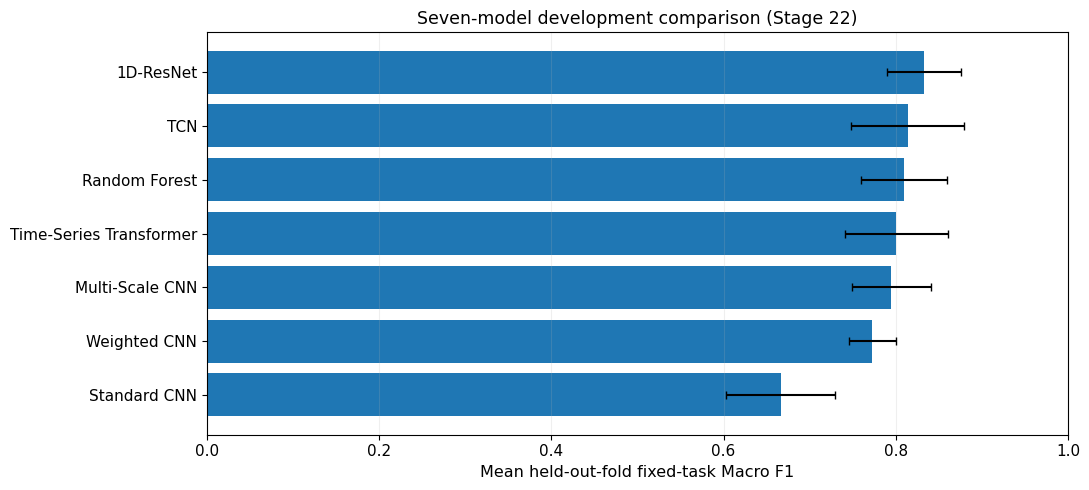

In [3]:
# ================ 02. Review Seven-Model Development Results =================

# --------------- 1. Summarise Seven-Model Development Evidence ---------------
benchmark=results["benchmark"].sort_values("macro_f1_mean",ascending=False)
display(benchmark.round(4))

# ----------------- 2. Visualise Macro F1 and Fold Variation ------------------
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(benchmark["model"],benchmark["macro_f1_mean"],
        xerr=benchmark["macro_f1_sd"],capsize=3)
ax.invert_yaxis()
ax.set(xlim=(0,1),xlabel="Mean held-out-fold fixed-task Macro F1",
       title="Seven-model development comparison (Stage 22)")
ax.grid(axis="x",alpha=.2)
fig.tight_layout()
save_figure(fig, output_dir / "24_development_model_selection_macro_f1.png")
plt.show()


**03. Inspect Stability Across Seeds and Folds**

Compare the predefined seeds `42`, `123` and `2026` across the same three Development GroupKFold splits and 400-update neural budget. Report mean and standard deviation descriptively. Repeated seeds on the same participants do not create independent evaluation cohorts.

In [4]:
# =============== 03. Inspect Stability Across Seeds and Folds ================

# ------------------- 1. Review Multi-Seed Loss Conditions --------------------
seed_summary=results["robustness_summary"].sort_values(
    "mean_across_seed_fold_macro_f1",ascending=False
)
display(seed_summary.round(4))

# -------------------- 2. Compare ResNet and TCN Stability --------------------
weighted=results["robustness_folds"].query("loss_method == 'weighted_ce'")
paired=weighted.pivot(index=["seed","fold"],columns="architecture",values="macro_f1")
paired["ResNet_minus_TCN"]=paired["1D-ResNet"]-paired["TCN"]
display(paired.round(4))
print("Mean matched-fold difference:",
      round(paired["ResNet_minus_TCN"].mean(),4))
print("This comparison is exploratory and development-only.")


,architecture,loss_method,mean_across_seed_fold_macro_f1,across_seed_sd,total_training_s
2,1D-ResNet,weighted_ce,0.8286,0.0052,101.8786
3,TCN,weighted_ce,0.8105,0.0079,30.0425
1,1D-ResNet,focal,0.8058,0.0053,107.3554
0,1D-ResNet,class_balanced,0.7915,0.0191,108.3910


architecture  1D-ResNet     TCN  ResNet_minus_TCN
seed fold                                        
42   1           0.7879  0.7634            0.0245
     2           0.8360  0.7898            0.0462
     3           0.8747  0.8883           -0.0136
123  1           0.7966  0.7876            0.0090
     2           0.8219  0.7554            0.0665
     3           0.8723  0.8616            0.0107
2026 1           0.8260  0.8167            0.0093
     2           0.7799  0.7487            0.0311
     3           0.8625  0.8831           -0.0206

Mean matched-fold difference: 0.0181
This comparison is exploratory and development-only.


**04. Evaluate Loss Choices and Minority-Class Trade-offs**

Weighted Cross-Entropy led the ResNet loss formulations in mean Development Macro F1 in Notebook 23. Focal and Class-Balanced Cross-Entropy are not uniformly better for minority activities. Random Forest retains stronger Shuffling F1 in the original matched benchmark, supporting its role as a fixed reference.

In [5]:
# ========== 04. Evaluate Loss Choices and Minority-Class Trade-offs ==========

# --------------------- 1. Compare ResNet Loss Trade-Offs ---------------------
resnet=results["robustness_folds"].query("architecture == '1D-ResNet'")
loss_table=resnet.pivot(index=["seed","fold"],columns="loss_method",values="macro_f1")
display(loss_table.round(4))
loss_means=resnet.groupby("loss_method",as_index=False)["macro_f1"].mean()
display(loss_means.sort_values("macro_f1",ascending=False).round(4))

# --------------------- 2. Review Minority-Class Outcomes ---------------------
class_report=results["benchmark_classes"].copy()
class_report=class_report[
    class_report["model"].isin(["Random Forest","1D-ResNet","TCN"])
    & class_report["class_code"].isin([3,4,5])
]
display(class_report[[
    "model","class_code","support","precision","recall","f1"
]].round(4))
assert len(class_report)==9


loss_method  class_balanced   focal  weighted_ce
seed fold                                       
42   1               0.7471  0.7687       0.7879
     2               0.7699  0.7807       0.8360
     3               0.8725  0.8681       0.8747
123  1               0.7823  0.7385       0.7966
     2               0.8030  0.8229       0.8219
     3               0.8376  0.8720       0.8723
2026 1               0.7624  0.8043       0.8260
     2               0.6843  0.7833       0.7799
     3               0.8644  0.8139       0.8625

,loss_method,macro_f1
2,weighted_ce,0.8286
1,focal,0.8058
0,class_balanced,0.7915


,model,class_code,support,precision,recall,f1
2,Random Forest,3,219,0.4756,0.5342,0.5032
3,Random Forest,4,192,0.7310,0.5521,0.6291
4,Random Forest,5,182,0.7031,0.4945,0.5806
26,TCN,3,219,0.2959,0.3973,0.3392
27,TCN,4,192,0.5385,0.8750,0.6667
28,TCN,5,182,0.5468,0.8022,0.6503
42,1D-ResNet,3,219,0.3422,0.4703,0.3962
43,1D-ResNet,4,192,0.5375,0.8594,0.6613
44,1D-ResNet,5,182,0.6946,0.7747,0.7325


**05. Recommend Primary and Reference Models**

The proposed primary model is 1D-ResNet with inverse-square-root weighted Cross-Entropy. Seed `42` is a reproducibility convention rather than a choice based on maximum observed performance. A 120-tree Random Forest is retained as a fixed classical reference; TCN remains part of the Development evidence without adding an unplanned candidate to later Test scoring.

The recommendation reflects mean fixed-task Macro F1, stability and known minority-class limitations; it is not a statistically confirmed claim of model-family superiority.

In [6]:
# ================ 05. Recommend Primary and Reference Models =================

# ------------------- 1. Verify Development-Based Selection -------------------
candidate=seed_summary.iloc[0]
assert candidate["architecture"]=="1D-ResNet"
assert candidate["loss_method"]=="weighted_ce"

# ----------------- 2. Document Primary and Reference Models ------------------
decision=pd.DataFrame([
    {"role":"Primary for proposed Stage 25","architecture":"1D-ResNet",
     "training":"Inverse-square-root Weighted CE","reason":"Highest mean Macro F1 across three seeds and three folds"},
    {"role":"Fixed classical reference","architecture":"Random Forest",
     "training":"Balanced-subsample RF","reason":"Higher observed Shuffling F1 in matched Stage 22"},
    {"role":"Development-only neural comparator","architecture":"TCN",
     "training":"Inverse-square-root Weighted CE","reason":"Strong development results; lower mean across seeds"},
    {"role":"Not selected","architecture":"ResNet Focal / Class-Balanced",
     "training":"Alternative loss ablations","reason":"Lower Stage 23 average fixed-eight-class Macro F1"},
])
display(decision)
print("Primary model candidate: 1D-ResNet + Weighted CE")
print("Proposed final seed: 42 (fixed convention, not best-seed tuning)")
print("No Test-based decision performed.")


,role,architecture,training,reason
0,Primary for proposed Stage 25,1D-ResNet,Inverse-square-root Weighted CE,Highest mean Macro F1 across three seeds and t...
1,Fixed classical reference,Random Forest,Balanced-subsample RF,Higher observed Shuffling F1 in matched Stage 22
2,Development-only neural comparator,TCN,Inverse-square-root Weighted CE,Strong development results; lower mean across ...
3,Not selected,ResNet Focal / Class-Balanced,Alternative loss ablations,Lower Stage 23 average fixed-eight-class Macro F1


Primary model candidate: 1D-ResNet + Weighted CE
Proposed final seed: 42 (fixed convention, not best-seed tuning)
No Test-based decision performed.


**06. Specify Source, Labels and Participant Roles**

Propose the pinned HARTH v2.0 source revision, six acceleration channels, nominal 50 Hz sampling, 100-sample windows, 50-sample stride, strict label purity, timestamp-continuity checks and activity codes 1–8. Exclude out-of-task codes after windowing and reserve S023/S032 for one separately qualified evaluation.

Use the same label-independent, 500-window-per-participant cap for all 29 Development participants rather than silently switching to the full 132,397-window cohort.

In [7]:
# ============= 06. Specify Source, Labels and Participant Roles ==============
source_protocol=pd.DataFrame([
    {"property":"Source revision","frozen_value":"dad2cfbe89a26f72f19770419469ac037de200df"},
    {"property":"Nominal sampling rate","frozen_value":"50 Hz"},
    {"property":"Window length","frozen_value":"100 samples (2 seconds)"},
    {"property":"Stride","frozen_value":"50 samples"},
    {"property":"Purity / continuity","frozen_value":"100% one documented source label; strict timestamp checks"},
    {"property":"Target class codes","frozen_value":"1, 2, 3, 4, 5, 6, 7, 8"},
    {"property":"Development","frozen_value":"29 people; chronological cap 500; 14,201 windows"},
    {"property":"Original reserved Test","frozen_value":"S023 and S032; no access in Stage 24"},
    {"property":"Original source axes","frozen_value":"Back and thigh accelerometer (three axes each)"},
])
display(source_protocol)
assert len(source_protocol)==9


,property,frozen_value
0,Source revision,dad2cfbe89a26f72f19770419469ac037de200df
1,Nominal sampling rate,50 Hz
2,Window length,100 samples (2 seconds)
3,Stride,50 samples
4,Purity / continuity,100% one documented source label; strict times...
5,Target class codes,"1, 2, 3, 4, 5, 6, 7, 8"
6,Development,"29 people; chronological cap 500; 14,201 windows"
7,Original reserved Test,S023 and S032; no access in Stage 24
8,Original source axes,Back and thigh accelerometer (three axes each)


**07. Propose Final Training Settings**

The primary ResNet configuration uses 400 Adam updates, batch size 128, learning rate `0.001` and seed `42`. Fit channel scaling and class weights on Development only and save them with the trained model. The reference Random Forest uses 30 statistical features, 120 trees, minimum leaf size three, balanced-subsample weights and seed `42`.

No calibration procedure is included because Notebook 19 did not show consistent improvement in NLL.

In [8]:
# ==================== 07. Propose Final Training Settings ====================
training_config=pd.DataFrame([
    {"setting":"Primary architecture","value":"1D-ResNet, hidden_channels=32"},
    {"setting":"Loss","value":"Fold/Development-only inverse-square-root Weighted CE"},
    {"setting":"Optimiser","value":"Adam, learning_rate=0.001"},
    {"setting":"Budget","value":"400 optimiser updates, batch size=128"},
    {"setting":"Seed","value":"42"},
    {"setting":"CNN preprocessing","value":"Development-only per-axis mean/SD; preserve channel order"},
    {"setting":"RF reference","value":"120 trees, min_samples_leaf=3, balanced_subsample"},
    {"setting":"Final checkpoint","value":"Last update only, no Test-driven selection"},
    {"setting":"Temperature scaling","value":"Not included"},
])
display(training_config)


,setting,value
0,Primary architecture,"1D-ResNet, hidden_channels=32"
1,Loss,Fold/Development-only inverse-square-root Weig...
2,Optimiser,"Adam, learning_rate=0.001"
3,Budget,"400 optimiser updates, batch size=128"
4,Seed,42
5,CNN preprocessing,Development-only per-axis mean/SD; preserve ch...
6,RF reference,"120 trees, min_samples_leaf=3, balanced_subsample"
7,Final checkpoint,"Last update only, no Test-driven selection"
8,Temperature scaling,Not included


**08. Predefine the Qualified Held-Out Evaluation**

Use fixed eight-class Macro F1 as the primary reported metric, with accuracy, balanced accuracy, confusion matrices, class-level precision/recall/F1, true support, participant-level scores and computational cost. The separately approved protocol prohibits using Test results to revise the architecture, seed, sampling, loss or number of training updates.

Because the reserved participants had earlier descriptive exposure and come from the same study, this is a qualified retrospective held-out evaluation, not a strictly blind external benchmark.

In [9]:
# ============== 08. Predefine the Qualified Held-Out Evaluation ==============
rules=pd.DataFrame([
    {"item":"Primary evaluation","fixed_rule":"Eight-class Macro F1 with original source class order"},
    {"item":"Secondary outcomes","fixed_rule":"Balanced accuracy, accuracy, class precision/recall/F1 and support"},
    {"item":"Participant reporting","fixed_rule":"Scores for both original reserved participants separately"},
    {"item":"Model comparisons","fixed_rule":"One primary ResNet and one fixed RF reference; no Test-guided choice"},
    {"item":"Preprocessing","fixed_rule":"Fit only on 29-person Development"},
    {"item":"Selection and stopping","fixed_rule":"400 final updates; no Test-based checkpoint selection"},
    {"item":"Unmapped labels","fixed_rule":"Preserve original codes; exclude post-windowing"},
    {"item":"Evidence limitation","fixed_rule":"Previously inspected reserved people, not strictly blind external Test"},
])
display(rules)


,item,fixed_rule
0,Primary evaluation,Eight-class Macro F1 with original source clas...
1,Secondary outcomes,"Balanced accuracy, accuracy, class precision/r..."
2,Participant reporting,Scores for both original reserved participants...
3,Model comparisons,One primary ResNet and one fixed RF reference;...
4,Preprocessing,Fit only on 29-person Development
5,Selection and stopping,400 final updates; no Test-based checkpoint se...
6,Unmapped labels,Preserve original codes; exclude post-windowing
7,Evidence limitation,"Previously inspected reserved people, not stri..."


**09. Verify the Frozen Stage 24 Protocol and Source Fingerprints**

Verify existing protocol lineage separately after the Development CSV comparison. Historical Stage 23/24 SHA256 fields refer to immutable original notebook executions (active Stages 22/23), not to the current CSV exports. Verify the six frozen source modules against the unchanged reconciled fingerprints. The original and reconciled proposals are immutable `PENDING_USER_REVIEW` records from the proposal phase. The separate, immutable approved manifest records the actual subsequent qualified-Test authorisation used in Stage 25. The displayed pending proposal status must not be re-labelled as an approval. This is a read-only replay: verify the frozen scientific settings and existing approval lineage without overwriting records, creating a new approval, refitting models or opening Test recordings. On Windows, only an exact CRLF-to-LF representation of otherwise unchanged source code is accepted.

In [10]:
# ====== 09. Verify the Frozen Stage 24 Protocol and Source Fingerprints ======

# Historical hashes are immutable lineage identifiers, not digests of the
# current Stage 22/23 CSV exports. Verify them only in this protocol section.
import json

# ------------------- 1. Verify Frozen Source Module Hashes -------------------
paths=[
    "code/python/src/core/advanced_temporal_models.py",
    "code/python/src/core/temporal_cnn.py",
    "code/python/src/core/temporal_benchmark.py",
    "code/python/src/core/feature_engineering.py",
    "code/python/src/core/robustness_experiments.py",
    "studies/wearable_activity_recognition/src/harth_data.py",
]
from core.harth_protocol_lineage import (
    verified_module_sha256, verify_preexisting_stage25_lineage,
    resolve_frozen_source_path,
)
evidence_dir=root/"wearable_activity_recognition/evidence"
reconciled=json.loads(
    (evidence_dir/"stage_25_protocol_proposal_reconciled.json").read_text(
        encoding="utf-8"
    )
)
expected_sha=reconciled["module_sha256"]
assert set(paths)==set(expected_sha), "Unexpected frozen source-module list."
code_sha={}
for name in paths:
    file=resolve_frozen_source_path(root,name)
    assert file.is_file(),name
    code_sha[name]=verified_module_sha256(file,expected_sha[name])

# ----------------- 2. Reconstruct Development-Based Proposal -----------------
manifest={
    "schema":"harth-final-protocol-v1",
    "status":"PENDING_USER_REVIEW",
    "source_development_sha256":reconciled["source_development_sha256"],
    "stage23_saved_notebook_sha256":reconciled["stage23_saved_notebook_sha256"],
    "stage24_saved_notebook_sha256":reconciled["stage24_saved_notebook_sha256"],
    "primary_model":{
        "architecture":"1D-ResNet","hidden_channels":32,"in_channels":6,
        "classes":list(range(1,9)),"training_loss":"inverse_sqrt_weighted_ce",
        "random_seed":42,"optimizer":"Adam","learning_rate":0.001,
        "batch_size":128,"optimizer_steps":400,"checkpoint":"final_step",
        "preprocessing":"Development-only per-channel mean and SD",
    },
    "reference_model":{
        "architecture":"Random Forest","n_estimators":120,
        "min_samples_leaf":3,"class_weight":"balanced_subsample",
        "seed":42,"features":["mean","std","rms","peak_to_peak","waveform_length"],
    },
    "source":{
        "dataset":"HARTH v2.0",
        "revision":"dad2cfbe89a26f72f19770419469ac037de200df",
        "sampling_rate_hz":50,"window_size":100,"step_size":50,
        "annotation_purity":1.0,"timestamp_continuity":True,
        "task_codes":list(range(1,9)),
        "development_participants":29,"cap_per_development_person":500,
        "expected_development_windows":14201,
        "reserved_test_people":["S023","S032"],
        "test_cap_per_person":500,
        "unknown_source_codes":"Preserve and exclude after time-safe windowing",
    },
    "evaluation":{
        "main_metric":"Fixed-eight-class Macro F1",
        "additional":["accuracy","balanced_accuracy",
                      "per-class precision/recall/F1/support",
                      "per-person fixed-task Macro F1","confusion matrices"],
        "use_test_for_tuning":False,
        "temperature_scaling":False,
        "description":"Qualified previously-inspected reserved Test, not fully blind external validation",
    },
    "module_sha256":code_sha,
}

# -------------------- 3. Check Immutable Protocol Lineage --------------------
lineage=verify_preexisting_stage25_lineage(manifest,evidence_dir)
print("Historical original proposal:",lineage["original_proposal"])
print("Reconciled pending protocol:",lineage["reconciled_proposal"])
print("Previous qualified-Test approval:",lineage["existing_approval"])
print("New authorisation granted by replay:",lineage["new_approval_granted"])
print("Protocol files written:",lineage["files_written"])
print("Code module SHA256 entries:",len(code_sha))
print("Historical Development source fingerprint:",reconciled["source_development_sha256"])
print("Historical notebook SHA256 identities retained: YES")
print("Current Stage 22/23 CSV byte identity verified by these hashes: NO")
print("Test recordings read during Stage 24: NO")


Historical original proposal: PRESERVED
Reconciled pending protocol: MATCHED
Previous qualified-Test approval: VERIFIED_EXISTING_ONLY
New authorisation granted by replay: False
Protocol files written: 0
Code module SHA256 entries: 6
Historical Development source fingerprint: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Historical notebook SHA256 identities retained: YES
Current Stage 22/23 CSV byte identity verified by these hashes: NO
Test recordings read during Stage 24: NO


**10. Summarise Selection Rationale and Historical Review**

Present the Development-based preference for weighted 1D-ResNet alongside Random Forest's Shuffling advantage and the remaining class-level limitations. The historical protocol review covered the primary model, reference classifier, 500-window cap, treatment of previously inspected S023/S032 and predefined evaluation metrics. Its original review requirements remain visible as provenance; the separately approved record and resulting qualified evaluation are preserved in Stage 25.

In [11]:
# ========== 10. Summarise Selection Rationale and Historical Review ==========
review=pd.DataFrame([
    {"item":"Primary final candidate","proposal":"1D-ResNet + Weighted CE","requires_approval":True},
    {"item":"Classic reference","proposal":"Random Forest 120-tree","requires_approval":True},
    {"item":"Bounded cohort","proposal":"500 source windows/person","requires_approval":True},
    {"item":"Held-out set","proposal":"S023, S032 (historically inspected)","requires_approval":True},
    {"item":"Single final seed","proposal":"42, fixed convention","requires_approval":True},
    {"item":"Allowed scoring","proposal":"One qualified held-out evaluation after approval","requires_approval":True},
])
display(review)
print("Development evidence supports this proposed configuration.")
print("Explicit user approval before Stage 25: REQUIRED")


,item,proposal,requires_approval
0,Primary final candidate,1D-ResNet + Weighted CE,True
1,Classic reference,Random Forest 120-tree,True
2,Bounded cohort,500 source windows/person,True
3,Held-out set,"S023, S032 (historically inspected)",True
4,Single final seed,"42, fixed convention",True
5,Allowed scoring,One qualified held-out evaluation after approval,True


Development evidence supports this proposed configuration.
Explicit user approval before Stage 25: REQUIRED


**11. Scientific Protocol Quality Gate**

Verify the referenced seven-model and 36-job Development evidence, explicit model settings, source fingerprints and absence of Test access in this decision stage. A passing gate checks proposal completeness and existing historical approval lineage; it does not fit a model, grant a new Test authorisation or establish independent generalisation.

In [12]:
# =================== 11. Scientific Protocol Quality Gate ====================

# ----------------------- 1. Verify Selection Evidence ------------------------
assert len(results["benchmark"])==7
assert len(results["robustness_folds"])==36
assert len(results["robustness_summary"])==4
assert manifest["status"]=="PENDING_USER_REVIEW"
assert lineage["reconciled_proposal"]=="MATCHED"
assert lineage["existing_approval"]=="VERIFIED_EXISTING_ONLY"
assert lineage["files_written"]==0
assert not lineage["new_approval_granted"]
assert manifest["source_development_sha256"]==reconciled["source_development_sha256"]
assert len(manifest["module_sha256"])==6
assert manifest["primary_model"]["architecture"]=="1D-ResNet"
assert manifest["primary_model"]["random_seed"]==42
assert manifest["primary_model"]["optimizer_steps"]==400
assert manifest["source"]["reserved_test_people"]==["S023","S032"]
assert not manifest["evaluation"]["use_test_for_tuning"]
assert manifest["evaluation"]["main_metric"]=="Fixed-eight-class Macro F1"

# -------------- 2. Report Quality Gate and Approval Boundaries ---------------
print("STAGE 24: FINAL MODEL SELECTION AND PROTOCOL PROPOSAL")
print("="*70)
print("Source-matched completed Development evidence: PASSED")
print("Seven-model Stage 22 evaluation reviewed: PASSED")
print("Three-seed/loss Stage 23 evidence reviewed: PASSED")
print("Primary development candidate: 1D-ResNet + Weighted CE")
print("Fixed reference model: Random Forest")
print("Protocol module/source digests: RECORDED")
print("Protected Test subjects loaded: NO")
print("-"*70)
print("Stage 24 development selection audit: PASSED")
print("Historical proposal status: PENDING USER REVIEW")
print("Previously approved qualified-Test lineage: VERIFIED")
print("New Test evaluation authorised: NO")
print("Test evaluation performed by this rerun: NO")
print("Next: review completion evidence before any further research stage")

# ------------------ 3. Save Reusable Development Selection Outputs ----------
benchmark.to_csv(output_dir / "24_development_model_ranking.csv", index=False)
seed_summary.to_csv(output_dir / "24_development_robustness_ranking.csv", index=False)
paired.rename_axis(index=["seed", "fold"]).reset_index().to_csv(
    output_dir / "24_resnet_tcn_paired_seed_fold_scores.csv", index=False
)
loss_table.reset_index().to_csv(
    output_dir / "24_resnet_loss_seed_fold_scores.csv", index=False
)
loss_means.to_csv(output_dir / "24_resnet_mean_loss_scores.csv", index=False)
class_report.to_csv(output_dir / "24_selection_minority_class_comparison.csv", index=False)
decision.to_csv(output_dir / "24_development_selection_decisions.csv", index=False)
source_protocol.to_csv(output_dir / "24_proposed_source_protocol.csv", index=False)
training_config.to_csv(output_dir / "24_proposed_training_configuration.csv", index=False)
rules.to_csv(output_dir / "24_qualified_evaluation_rules.csv", index=False)
review.to_csv(output_dir / "24_historical_selection_review.csv", index=False)
print("Saved Development-only selection tables in:", output_dir)
print("Existing approved protocol and proposal files: NOT MODIFIED")

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="24")

STAGE 24: FINAL MODEL SELECTION AND PROTOCOL PROPOSAL
Source-matched completed Development evidence: PASSED
Seven-model Stage 22 evaluation reviewed: PASSED
Three-seed/loss Stage 23 evidence reviewed: PASSED
Primary development candidate: 1D-ResNet + Weighted CE
Fixed reference model: Random Forest
Protocol module/source digests: RECORDED
Protected Test subjects loaded: NO
----------------------------------------------------------------------
Stage 24 development selection audit: PASSED
Historical proposal status: PENDING USER REVIEW
Previously approved qualified-Test lineage: VERIFIED
New Test evaluation authorised: NO
Test evaluation performed by this rerun: NO
Next: review completion evidence before any further research stage
Saved Development-only selection tables in: /content/human-movement-intelligence/wearable_activity_recognition/output
Existing approved protocol and proposal files: NOT MODIFIED
------------------------------------------------------------------------
Notebook s